In [2]:
from forecast import load_prices, train_test_split_time, seasonal_naive_forecast, mae

prices = load_prices()
train, test = train_test_split_time(prices, test_weeks=8)
print(f"train: {train.index.min()} -> {train.index.max()} ({len(train)} hours)")
print(f"test:  {test.index.min()} -> {test.index.max()} ({len(test)} hours)")

train: 2025-10-20 00:00:00+02:00 -> 2026-08-20 23:00:00+02:00 (7320 hours)
test:  2026-08-21 00:00:00+02:00 -> 2026-10-15 23:00:00+02:00 (1344 hours)


In [3]:
# Shift the FULL price series (not just the test slice - see forecast.py for why),
# then evaluate only against the test window.
naive_forecast_full = seasonal_naive_forecast(prices)
naive_forecast_test = naive_forecast_full.loc[test.index]

baseline_mae = mae(test["price_eur_mwh"], naive_forecast_test)
mean_test_price = test["price_eur_mwh"].mean()
print(f"Baseline MAE: {baseline_mae:.2f} EUR/MWh")
print(f"Mean test price: {mean_test_price:.2f} EUR/MWh")
print(f"MAE as % of mean price: {100 * baseline_mae / mean_test_price:.1f}%")

Baseline MAE: 53.53 EUR/MWh
Mean test price: 144.30 EUR/MWh
MAE as % of mean price: 37.1%


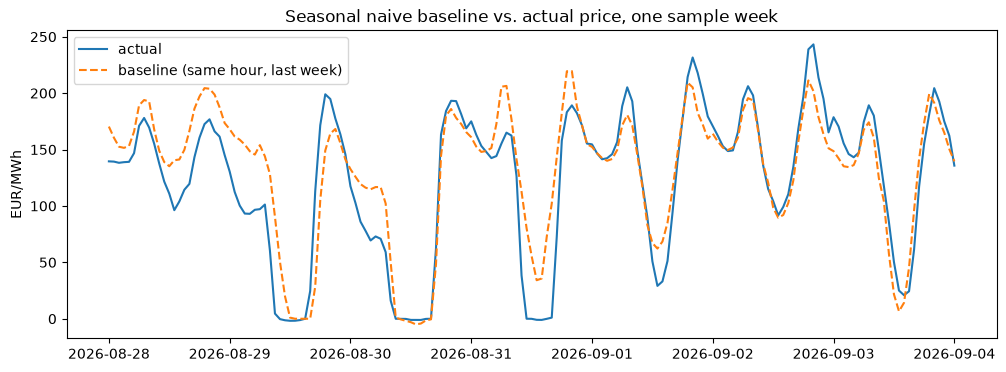

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Sanity-check on one real week from the test period: does the baseline
# track the actual shape, or is it just lucky on average?
sample_start = test.index.min() + pd.Timedelta(days=7)
sample_end = sample_start + pd.Timedelta(days=7)
sample_actual = test["price_eur_mwh"].loc[sample_start:sample_end]
sample_pred = naive_forecast_test.loc[sample_start:sample_end]

plt.figure(figsize=(12, 4))
plt.plot(sample_actual.index, sample_actual, label="actual")
plt.plot(sample_pred.index, sample_pred, label="baseline (same hour, last week)", linestyle="--")
plt.ylabel("EUR/MWh")
plt.legend()
plt.title("Seasonal naive baseline vs. actual price, one sample week")
plt.show()